In [1]:
import torch
import torchvision.transforms.functional as F
from PIL import Image
from torchvision.transforms import v2

from src.model.bae import BinaryAutoEncoder

In [ ]:
# C64: 256x256x3 -> 16x16x64   --  https://drive.google.com/file/d/1DSS0gY2L4bvvK2vtoC6lwzwEJ39K_Z0O
autoencoder = BinaryAutoEncoder.from_pretrained('../assets/binaryae_ema_8100000.th')

# C128: 256x256x3 -> 16x16x128  --  https://drive.google.com/file/d/1qGERs5qH1AHjd8QLS7N-n33OobtHQEoA
# autoencoder = BinaryAutoEncoder.from_pretrained(
#     'assets/binaryae_ema_10200000.th', codebook_size=128, decoder_mult=3
# )

print(autoencoder.eval())

BinaryAutoEncoder(
  (encoder): Encoder(
    (blocks): ModuleList(
      (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1-2): 2 x ResBlock(
        (block): Sequential(
          (0): GroupNorm(32, 128, eps=1e-06, affine=True, bias=True)
          (1): SiLU(inplace=True)
          (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (3): GroupNorm(32, 128, eps=1e-06, affine=True, bias=True)
          (4): SiLU(inplace=True)
          (5): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
        (shortcut): Identity()
      )
      (3): Downsample(
        (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
      )
      (4-5): 2 x ResBlock(
        (block): Sequential(
          (0): GroupNorm(32, 128, eps=1e-06, affine=True, bias=True)
          (1): SiLU(inplace=True)
          (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (3): GroupNorm(32, 128, eps=

In [3]:
if torch.cuda.is_available():
    device = 'cuda:0'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
dtype = torch.float32
autoencoder.to(device, dtype);

torch.Size([1, 3, 256, 256])


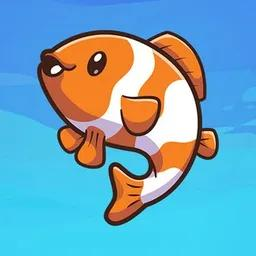

In [4]:
crop = v2.Compose([v2.Resize(256), v2.CenterCrop(256)])
to_tensor = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

img = crop(Image.open('../assets/fish.jpg').convert('RGB'))
x = to_tensor(img).unsqueeze(0).to(device, dtype)
print(x.shape)
img

In [5]:
with torch.inference_mode():
    out = autoencoder(x, deterministic=False)
out['recon'].shape

torch.Size([1, 3, 256, 256])

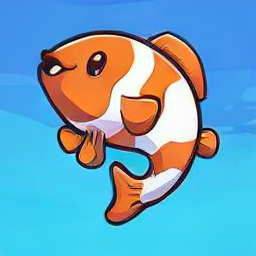

In [6]:
F.to_pil_image(out['recon'].squeeze(0).cpu())

In [7]:
with torch.inference_mode():
    binary = autoencoder.encode(x, deterministic=False, code_only=True)
print(binary.shape)
binary[:, 0, :, :]

torch.Size([1, 64, 16, 16])


tensor([[[1., 0., 1., 0., 1., 1., 1., 1., 1., 1., 0., 0., 1., 1., 1., 1.],
         [1., 0., 1., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 1.],
         [1., 1., 0., 1., 0., 1., 0., 1., 1., 0., 1., 1., 1., 0., 0., 1.],
         [1., 1., 1., 1., 1., 0., 1., 1., 0., 1., 0., 0., 1., 1., 0., 1.],
         [0., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 1.],
         [0., 1., 1., 1., 0., 0., 0., 0., 1., 1., 1., 0., 0., 1., 1., 0.],
         [0., 0., 1., 1., 1., 0., 1., 1., 1., 1., 0., 0., 0., 1., 1., 0.],
         [1., 0., 1., 0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 0., 1., 0.],
         [1., 1., 1., 1., 1., 0., 1., 1., 0., 1., 0., 0., 0., 0., 1., 0.],
         [1., 1., 0., 0., 1., 0., 1., 0., 1., 1., 0., 0., 0., 1., 0., 0.],
         [1., 1., 1., 1., 0., 0., 1., 1., 1., 0., 0., 1., 1., 0., 0., 1.],
         [0., 1., 0., 0., 1., 1., 0., 1., 0., 0., 1., 1., 1., 1., 1., 1.],
         [1., 0., 1., 0., 1., 1., 0., 1., 0., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1.,